# 05 — Profit analysis (step 7)

**Purpose.** Put money on each decision: is it worth sending a "please come back" offer, to whom,
and does the answer survive different cost assumptions? Uses the test-month predictions saved by
notebook 04; the profit formulas are in `src/evaluation.py`.

**Assumptions (main case):**

| Assumption | Value | Why |
|---|---|---|
| Offer cost | £10 per contacted customer | discount voucher plus handling |
| Success rate | 20% of churners who get an offer stay | an assumption: only an experiment can measure it |
| Margin | 25% of spend | typical for a gift wholesaler |
| Value of a saved customer | margin × their spend over the past 365 days | one more year of buying |

Only customers who would have churned can be saved; offers to customers who would have stayed
anyway cost money and recover nothing.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import PROCESSED_DIR
from src.evaluation import bootstrap_ci, expected_value_contact, offer_gain, realized_profit

FIG = ROOT / "reports" / "figures"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.float_format", "{:,.0f}".format)

pred = pd.read_parquet(PROCESSED_DIR / "test_predictions.parquet")   # written by notebook 04
y, spend, groups = pred["churn"].to_numpy(), pred["spend_365d"].to_numpy(), pred["customer_id"].to_numpy()
COST, SUCCESS, MARGIN = 10, 0.20, 0.25

## 1. Who gets an offer?

Five targeting policies on the test months:

* **Nobody / everybody:** the two extremes.
* **Value only:** expected-value rule with the same churn chance for everyone (the training churn
  rate), so only spend decides. This isolates what the churn model adds.
* **Expected value, Logistic raw / Boosting all:** contact a customer when
  *predicted churn chance × success rate × margin × spend* is more than the offer cost.

In [2]:
def policies(cost=COST, success=SUCCESS, margin=MARGIN):
    ev = lambda p: expected_value_contact(p, spend, cost, success, margin)
    return {
        "Nobody": np.zeros(len(y), bool),
        "Everybody": np.ones(len(y), bool),
        "Value only": ev(pred["train_churn_rate"].to_numpy()),
        "Expected value, Logistic raw": ev(pred["p_logistic_raw"].to_numpy()),
        "Expected value, Boosting all": ev(pred["p_boosting_all"].to_numpy()),
    }

def profit(contact, ix=None, cost=COST, success=SUCCESS, margin=MARGIN):
    ix = np.arange(len(y)) if ix is None else ix
    return realized_profit(contact[ix], y[ix], spend[ix], cost, success, margin)

rows = {}
for name, contact in policies().items():
    lo, hi = bootstrap_ci(lambda ix: profit(contact, ix), groups)
    rows[name] = {"customers contacted": contact.sum(), "share contacted": f"{contact.mean():.0%}",
                  "churners reached": (contact & (y == 1)).sum(), "profit (£)": profit(contact),
                  "95% CI (£)": f"{lo:,.0f} to {hi:,.0f}"}
pd.DataFrame(rows).T

,customers contacted,share contacted,churners reached,profit (£),95% CI (£)
Nobody,0,0%,0,0,0 to 0
Everybody,12964,100%,7291,"170,875","137,027 to 208,287"
Value only,9549,74%,4571,"180,720","147,000 to 217,775"
"Expected value, Logistic raw",10389,80%,5319,"177,724","145,976 to 212,929"
"Expected value, Boosting all",10050,78%,5263,"183,673","150,532 to 221,496"


## 2. Is the model's targeting really better?

Paired profit differences on the same resampled customers.

In [3]:
pol = policies()
def gap(a, b):
    point = profit(pol[a]) - profit(pol[b])
    lo, hi = bootstrap_ci(lambda ix: profit(pol[a], ix) - profit(pol[b], ix), groups)
    return f"£{point:+,.0f} (£{lo:+,.0f} to £{hi:+,.0f})"

pd.Series({f"{a} vs {b}": gap(a, b) for a, b in [
    ("Expected value, Boosting all", "Value only"),
    ("Expected value, Boosting all", "Expected value, Logistic raw"),
    ("Expected value, Boosting all", "Everybody"),
]}, name="profit difference (95% CI)").to_frame()

,profit difference (95% CI)
"Expected value, Boosting all vs Value only","£+2,953 (£+1,643 to £+4,217)"
"Expected value, Boosting all vs Expected value, Logistic raw","£+5,949 (£+869 to £+13,807)"
"Expected value, Boosting all vs Everybody","£+12,798 (£+11,402 to £+14,271)"


## 3. Profit curve

Customers ranked three ways, contacting the top share of each ranking: by expected value saved
(Boosting all), by churn chance alone, and at random. The peak of each curve is the best share to
contact in hindsight.

expected value     best: contact top 72%, profit £184,243
churn chance only  best: contact top 98%, profit £173,102
random             best: contact top 100%, profit £170,875


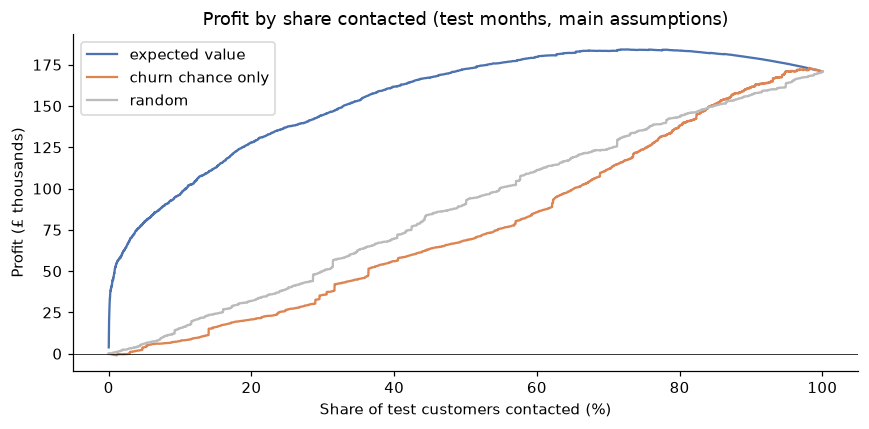

In [4]:
rank_ev = -(pred["p_boosting_all"] * spend).to_numpy()
rank_risk = -pred["p_boosting_all"].to_numpy()
rank_random = np.random.default_rng(0).permutation(len(y))
gain = offer_gain(y, spend, SUCCESS, MARGIN) - COST
shares = np.arange(1, len(y) + 1) / len(y)

fig, ax = plt.subplots(figsize=(8, 4))
for label, order, color in [("expected value", np.argsort(rank_ev), "#4C72B0"),
                            ("churn chance only", np.argsort(rank_risk), "#DD8452"),
                            ("random", rank_random, "#BBBBBB")]:
    curve = np.cumsum(gain[order]) / 1e3
    ax.plot(shares * 100, curve, color=color, label=label)
    best = curve.argmax()
    print(f"{label:18s} best: contact top {shares[best]:.0%}, profit £{curve[best]*1e3:,.0f}")
ax.axhline(0, color="black", lw=0.5)
ax.set_xlabel("Share of test customers contacted (%)"); ax.set_ylabel("Profit (£ thousands)")
ax.set_title("Profit by share contacted (test months, main assumptions)"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "05_profit_curve.png"); plt.show()

## 4. Sensitivity: does the answer hold if the assumptions change?

Offer cost from £5 to £50 and success rate from 10% to 30% (margin and success rate only matter
through their product, so margin stays at 25%).

In [5]:
grid = []
for cost in (5, 10, 25, 50):
    for success in (0.10, 0.20, 0.30):
        p = policies(cost, success)
        prof = {k: profit(v, cost=cost, success=success) for k, v in p.items()}
        best = max(prof, key=prof.get)
        grid.append({"offer cost (£)": cost, "success rate": f"{success:.0%}", "best policy": best,
                     "share contacted by best": f"{p[best].mean():.0%}",
                     "Boosting EV profit (£)": prof["Expected value, Boosting all"],
                     "vs value only (£)": prof["Expected value, Boosting all"] - prof["Value only"],
                     "vs everybody (£)": prof["Expected value, Boosting all"] - prof["Everybody"]})
pd.DataFrame(grid)

,offer cost (£),success rate,best policy,share contacted by best,Boosting EV profit (£),vs value only (£),vs everybody (£)
0,5,10%,"Expected value, Boosting all",78%,"91,836","1,476","6,399"
1,5,20%,"Expected value, Boosting all",93%,"237,528",917,"1,833"
2,5,30%,"Expected value, Boosting all",97%,"386,587",171,635
3,10,10%,"Expected value, Boosting all",48%,"54,006","4,680","33,388"
4,10,20%,"Expected value, Boosting all",78%,"183,673","2,953","12,798"
5,10,30%,"Expected value, Boosting all",87%,"328,048","3,052","6,916"
6,25,10%,"Expected value, Boosting all",10%,"22,816","30,708","196,658"
7,25,20%,"Expected value, Boosting all",38%,"85,267","16,237","108,852"
8,25,30%,"Expected value, Boosting all",56%,"192,692","9,286","66,020"
9,50,10%,"Expected value, Boosting all",2%,"19,124","46,871","517,067"


## 5. Where the profit comes from

Spend is very uneven (median £640 a year, top customer £267,000), so a few large customers can
dominate the totals. Share of the Boosting-EV profit coming from the top 1% of spenders:

In [6]:
contact = pol["Expected value, Boosting all"]
per_customer = np.where(contact, gain, 0)
top1 = spend >= np.quantile(spend, 0.99)
print(f"top 1% of spenders: {per_customer[top1].sum() / per_customer.sum():.0%} of profit; "
      f"without them the policy still makes £{per_customer[~top1].sum():,.0f}")

top 1% of spenders: 18% of profit; without them the policy still makes £149,861


## 6. Findings

1. **Targeting with the boosting model's expected-value rule is the most profitable policy in all 12
   cost and success-rate scenarios.**
2. **Main case (£10 offer, 20% success, 25% margin):** £183,700 on the test months, against
   £170,900 for contacting everybody (+£12,800, 95% CI £11,400 to £14,300) and £180,700 for
   targeting by spend alone (+£3,000, CI £1,600 to £4,200). It contacts 78% of customers; the best
   share in hindsight was 72%, so the rule picks close to the right amount without tuning.
3. **The model matters most when offers are expensive.** At £50 per offer, contacting everybody
   loses £200,000–£500,000, while the model's rule contacts 2–24% of customers, stays profitable and
   beats spend-only targeting by £47,000–£61,000.
4. **Large customers matter but don't drive the result:** the top 1% of spenders give 18% of the
   profit; without them the policy still makes about £150,000.
5. **Limit:** the profit levels depend entirely on the assumed 20% success rate. The ranking of
   policies holds across 10–30%, but the real success rate can only be measured by sending offers
   to a random half of flagged customers and comparing churn between the two halves.